# Phát hiện bất thường trong dữ liệu cảm biến IoT bằng Isolation Forest

Notebook thực hành trên **Intel Berkeley Research Lab Sensor Data**: tải dữ liệu thô → làm sạch → chuẩn hóa → huấn luyện → trực quan hóa → xuất CSV → đánh giá bán tổng hợp.

**Thiết kế mặc định:** node 1 và 2; so sánh nhiệt độ với nhiệt độ + điện áp; cùng các bản ghi hợp lệ; 70% đầu theo thời gian để huấn luyện, phần còn lại để kiểm tra. Hai node là lựa chọn minh họa cố định, không đại diện thống kê cho toàn mạng; bảng chất lượng bên dưới giúp kiểm tra lựa chọn này.

Chạy từ thư mục dự án bằng **Run All** sau khi cài `requirements.txt`. Lần đầu cần mạng để tải khoảng 34 MB; lần sau dùng lại tệp đã có. Các đầu ra được ghi lại trong `outputs/`, riêng phiếu nhận xét thủ công đã tồn tại được giữ nguyên.


## 1. Nguồn dữ liệu và cách đọc kết quả

[Nguồn Intel Lab Data tại MIT CSAIL](https://db.csail.mit.edu/labdata/labdata.html) mô tả 54 node đo nhiệt độ (°C), độ ẩm (%), ánh sáng (lux), điện áp (V), với chu kỳ danh nghĩa khoảng 31 giây trong năm 2004. Dữ liệu có khoảng trống; `epoch` là số thứ tự đo, **không phải Unix timestamp**.

Schema: `date time epoch node_id temperature humidity light voltage`. Không có cột nhãn bất thường thật. Một điểm bị Isolation Forest đánh dấu chỉ là **điểm nghi bất thường**, chưa xác nhận cảm biến hỏng.

Isolation Forest cô lập các quan sát bằng những phép chia ngẫu nhiên; điểm dễ cô lập thường có hành vi khác phần lớn dữ liệu. Trong scikit-learn, `predict=-1` và `decision_function<0` biểu thị điểm bị đánh dấu. `contamination=0.02` là giả định chọn ngưỡng, không phải tỷ lệ lỗi đã biết. Tỷ lệ trên train sẽ gần 2%; trên test có thể khác nhiều khi phân phối thay đổi. [Tài liệu IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)

StandardScaler được dùng theo yêu cầu bài thực hành. Mô hình cây không đòi hỏi chuẩn hóa như mô hình dựa trên khoảng cách. Chỉ fit scaler trên train. Timestamp dùng để chia tập và vẽ, không đưa vào mô hình: thí nghiệm này phát hiện giá trị/tổ hợp khác thường, chưa học quy luật chuỗi thời gian. [Tránh rò rỉ dữ liệu](https://scikit-learn.org/stable/common_pitfalls.html)


In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import StringIO
import gzip
import hashlib
import importlib.metadata
import json
import platform
import shutil
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

NODE_IDS = [1, 2]
FEATURE_SETS = {
    "temperature": ["temperature"],
    "temperature_voltage": ["temperature", "voltage"],
}
TRAIN_FRACTION = 0.70
CONTAMINATION = 0.02
RANDOM_STATE = 42
N_ESTIMATORS = 200
INJECTION_RATE = 0.05

DATA_URL = "https://db.csail.mit.edu/labdata/data.txt.gz"
RAW_PATH = Path("data/raw/data.txt.gz")  # Có thể đổi thành data/raw/data.txt.
OUT_DIR = Path("outputs")
DATA_CHECK_DIR = OUT_DIR / "data_checks"
PREDICTION_DIR = OUT_DIR / "predictions"
EVALUATION_DIR = OUT_DIR / "evaluation"
FIG_DIR = EVALUATION_DIR / "figures"
for directory in (DATA_CHECK_DIR, PREDICTION_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)
COLUMNS = ["date", "time", "epoch", "node_id", "temperature", "humidity", "light", "voltage"]
REQUIRED_FEATURES = sorted({feature for values in FEATURE_SETS.values() for feature in values})
assert 1 <= len(NODE_IDS) <= 2 and len(set(NODE_IDS)) == len(NODE_IDS)
assert all(isinstance(node, int) and 1 <= node <= 54 for node in NODE_IDS)
assert 0 < TRAIN_FRACTION < 1 and 0 < CONTAMINATION <= 0.5
assert 0 < INJECTION_RATE < 1
assert FEATURE_SETS.get("temperature") == ["temperature"]
assert FEATURE_SETS.get("temperature_voltage") == ["temperature", "voltage"]
assert set(REQUIRED_FEATURES) <= {"temperature", "humidity", "light", "voltage"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})


## 2. Tải và nạp dữ liệu

Tệp tải được kiểm tra gzip trước khi đổi tên, để lần chạy bị ngắt không để lại tệp có vẻ hoàn chỉnh. Nếu mạng không truy cập được MIT, tải thủ công [data.txt.gz](https://db.csail.mit.edu/labdata/data.txt.gz) vào `data/raw/` rồi chạy lại.

**Bẫy định dạng:** dùng dấu cách đơn `sep=" "`; không dùng `sep=r"\s+"` hay `split()`, vì chúng gộp ô trống và có thể làm lệch cột. Đọc theo chunk để chỉ giữ dữ liệu của node được chọn trong bộ nhớ. `raw_line` là số dòng 1-based trong tệp gốc, giúp truy vết.


In [2]:
def download_data(path):
    if path.exists():
        if path.stat().st_size == 0:
            raise ValueError(f"Tệp rỗng: {path}. Hãy thay bằng bản dữ liệu hợp lệ.")
        return
    if path.suffix != ".gz":
        raise FileNotFoundError(f"Hãy đặt dữ liệu thô tại {path} hoặc dùng RAW_PATH mặc định.")
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_suffix(".gz.part")
    try:
        with urlopen(DATA_URL, timeout=60) as response, partial.open("wb") as target:
            shutil.copyfileobj(response, target)
        with gzip.open(partial, "rb") as source:
            while source.read(1024 * 1024):
                pass
        partial.replace(path)
    except Exception as exc:
        partial.unlink(missing_ok=True)
        raise RuntimeError(
            f"Không tải được dữ liệu. Tải {DATA_URL} thủ công vào {path} rồi chạy lại."
        ) from exc


def read_sensor_chunks(source):
    return pd.read_csv(
        source, sep=" ", names=COLUMNS, header=None, dtype="string",
        chunksize=200_000, on_bad_lines="error", skip_blank_lines=False,
    )


def load_nodes(path, node_ids):
    parts = []
    total_rows = 0
    invalid_node_rows = 0
    for chunk in read_sensor_chunks(path):
        node = pd.to_numeric(chunk["node_id"], errors="coerce")
        valid_node = node.between(1, 54) & node.eq(node.round())
        invalid_node_rows += int((~valid_node.fillna(False)).sum())
        selected = chunk.loc[node.isin(node_ids)].copy()
        selected["raw_line"] = selected.index + 1
        parts.append(selected)
        total_rows += len(chunk)
    raw = pd.concat(parts, ignore_index=True)
    if raw.empty:
        raise ValueError(f"Không tìm thấy node {node_ids} trong {path}.")
    for column in COLUMNS[2:]:
        raw[column] = pd.to_numeric(raw[column], errors="coerce").astype("float64")
    raw["node_id"] = raw["node_id"].astype(int)
    raw["timestamp"] = pd.to_datetime(
        raw["date"] + " " + raw["time"], format="mixed", errors="coerce"
    )
    return raw, {"total_raw_rows": total_rows, "invalid_node_rows": invalid_node_rows}


# Kiểm tra hồi quy: điện áp phải ở đúng cột khi ba phép đo trước bị thiếu.
fixture = "2004-03-30 08:11:56.681052 53671 3    2.1997\n"
parsed = next(read_sensor_chunks(StringIO(fixture)))
assert parsed.loc[0, ["temperature", "humidity", "light"]].isna().all()
assert float(parsed.loc[0, "voltage"]) == 2.1997

download_data(RAW_PATH)
raw, load_audit = load_nodes(RAW_PATH, NODE_IDS)
with RAW_PATH.open("rb") as source:
    raw_sha256 = hashlib.file_digest(source, "sha256").hexdigest()
print(load_audit)
print(f"Đã chọn {len(raw):,} dòng từ node {NODE_IDS}; SHA-256: {raw_sha256}")
display(raw.head())


{'total_raw_rows': 2313682, 'invalid_node_rows': 10392}
Đã chọn 89,962 dòng từ node [1, 2]; SHA-256: d99288c8f406ca6604d359ceaa0d8adfffa79e7095061a1e27dc4399f48c7225


,date,time,epoch,node_id,temperature,humidity,light,voltage,raw_line,timestamp
0,2004-03-31,03:38:15.757551,2.0,1,122.1530,-3.91901,11.04,2.03397,1,2004-03-31 03:38:15.757551
1,2004-02-28,00:59:16.02785,3.0,1,19.9884,37.09330,45.08,2.69964,2,2004-02-28 00:59:16.027850
2,2004-02-28,01:03:16.33393,11.0,1,19.3024,38.46290,45.08,2.68742,3,2004-02-28 01:03:16.333930
3,2004-02-28,01:06:16.013453,17.0,1,19.1652,38.80390,45.08,2.68742,4,2004-02-28 01:06:16.013453
4,2004-02-28,01:06:46.778088,18.0,1,19.1750,38.83790,45.08,2.69964,5,2004-02-28 01:06:46.778088


## 3. Làm sạch và khảo sát node

Loại dòng không có timestamp hợp lệ, thiếu/không hữu hạn ở đặc trưng đang so sánh, rồi loại bản ghi trùng hoàn toàn. Hai cấu hình dùng **cùng tập dòng đầy đủ trên hợp các đặc trưng**, nên mẫu số so sánh giống nhau; đổi lại, mô hình chỉ nhiệt độ cũng bỏ các dòng thiếu điện áp.

Giữ nguyên các giá trị hữu hạn cực đoan để mô hình có thể phát hiện chúng. Không nội suy khoảng trống, không ép tần suất đo, không loại theo z-score hoặc khoảng nhiệt độ. Thiếu độ ẩm/ánh sáng không làm loại dòng khi hai thuộc tính này không được sử dụng. Bảng làm sạch ghi số loại theo từng bước, không đếm trùng.


In [3]:
def clean_nodes(raw_data):
    cleaned_parts, report = [], []
    for node in NODE_IDS:
        group = raw_data.loc[raw_data["node_id"].eq(node)].copy()
        raw_count = len(group)
        valid_time = group["timestamp"].notna()
        bad_time = int((~valid_time).sum())
        group = group.loc[valid_time]
        finite = np.isfinite(group[REQUIRED_FEATURES].to_numpy(dtype=float)).all(axis=1)
        bad_features = int((~finite).sum())
        group = group.loc[finite]
        before_dedup = len(group)
        group = group.drop_duplicates(subset=COLUMNS)
        duplicate_count = before_dedup - len(group)
        group = group.sort_values(["timestamp", "raw_line"], kind="stable").reset_index(drop=True)
        if len(group) < 30:
            raise ValueError(f"Node {node} chỉ còn {len(group)} dòng; cần ít nhất 30.")
        cleaned_parts.append(group)
        report.append({
            "node_id": node, "raw_rows": raw_count,
            "invalid_timestamp": bad_time, "missing_or_nonfinite_features": bad_features,
            "exact_duplicates": duplicate_count, "clean_rows": len(group),
            "removed_pct": 100 * (raw_count - len(group)) / raw_count,
        })
    return pd.concat(cleaned_parts, ignore_index=True), pd.DataFrame(report)


clean, cleaning_report = clean_nodes(raw)
profiles = []
for node, group in clean.groupby("node_id", sort=True):
    gaps = group["timestamp"].diff().dt.total_seconds()
    profiles.append({
        "node_id": node, "start": group["timestamp"].min(), "end": group["timestamp"].max(),
        "n_readings": len(group), "median_gap_seconds": gaps.median(),
        "max_gap_hours": gaps.max() / 3600, "gaps_over_5min": int(gaps.gt(300).sum()),
        "temperature_min": group["temperature"].min(),
        "temperature_max": group["temperature"].max(),
        "voltage_min": group["voltage"].min(), "voltage_max": group["voltage"].max(),
    })
node_profile = pd.DataFrame(profiles)
display(cleaning_report)
display(node_profile)
display(clean.groupby("node_id")[REQUIRED_FEATURES].agg(["min", "median", "max"]))


,node_id,raw_rows,invalid_timestamp,missing_or_nonfinite_features,exact_duplicates,clean_rows,removed_pct
0,1,43047,0,0,0,43047,0.0
1,2,46915,0,0,0,46915,0.0


,node_id,start,end,n_readings,median_gap_seconds,max_gap_hours,gaps_over_5min,temperature_min,temperature_max,voltage_min,voltage_max
0,1,2004-02-28 00:59:16.027850,2004-03-31 04:59:46.620093,43047,35.236370,24.467818,654,17.1954,122.153,2.006490,2.76242
1,2,2004-02-28 01:08:16.776717,2004-04-01 04:34:48.130427,46915,35.573509,24.464132,528,3.4068,122.153,0.018037,2.72440


temperature                     voltage                  
                min   median      max       min   median      max
node_id                                                          
1           17.1954  22.1444  122.153  2.006490  2.58226  2.76242
2            3.4068  22.4286  122.153  0.018037  2.48502  2.72440

## 4. Chia theo thời gian, chuẩn hóa và huấn luyện

Mỗi node có mô hình riêng. Ngưỡng thời gian lấy gần vị trí 70%; các dòng cùng timestamp nằm cùng phía để tránh giao nhau. `Pipeline(StandardScaler, IsolationForest)` được fit chỉ trên train, sau đó dự đoán cả train và test để thống kê riêng từng phần.

Các tham số và seed được giữ cố định giữa các cấu hình. Không điều chỉnh ngưỡng dựa vào điểm số ở phần đánh giá. Những giá trị lớn hơn bình thường trong train vẫn được giữ: học không giám sát không đảm bảo train hoàn toàn sạch.


In [4]:
def make_detector():
    return make_pipeline(
        StandardScaler(),
        IsolationForest(
            n_estimators=N_ESTIMATORS, contamination=CONTAMINATION,
            random_state=RANDOM_STATE, n_jobs=-1,
        ),
    )


models, splits, result_parts = {}, {}, []
for node, group in clean.groupby("node_id", sort=True):
    group = group.reset_index(drop=True).copy()
    boundary = group["timestamp"].iloc[int(len(group) * TRAIN_FRACTION)]
    group["split"] = np.where(group["timestamp"].lt(boundary), "train", "test")
    train = group.loc[group["split"].eq("train")].copy()
    test = group.loc[group["split"].eq("test")].copy()
    if len(train) < 20 or len(test) < 2:
        raise ValueError(f"Node {node} không đủ dữ liệu ở hai phía ngưỡng thời gian.")
    assert train["timestamp"].max() < test["timestamp"].min()
    splits[node] = (train, test)
    for feature_set, features in FEATURE_SETS.items():
        model = make_detector()
        model.fit(train[features])
        models[node, feature_set] = model
        result = group.copy()
        result["feature_set"] = feature_set
        result["decision_score"] = model.decision_function(group[features])
        result["is_anomaly"] = model.predict(group[features]) == -1
        result_parts.append(result)

predictions = pd.concat(result_parts, ignore_index=True)
anomalies = predictions.loc[predictions["is_anomaly"]].copy()
summary_input = pd.concat([predictions, predictions.assign(split="all")], ignore_index=True)
anomaly_summary = (
    summary_input.groupby(["node_id", "feature_set", "split"])["is_anomaly"]
    .agg(n_points="size", n_anomalies="sum").reset_index()
)
anomaly_summary["anomaly_pct"] = (
    100 * anomaly_summary["n_anomalies"] / anomaly_summary["n_points"]
)
display(anomaly_summary.round(3))
display(anomalies.nsmallest(10, "decision_score")[
    ["node_id", "timestamp", "feature_set", "split", "temperature", "voltage", "decision_score"]
])


,node_id,feature_set,split,n_points,n_anomalies,anomaly_pct
0,1,temperature,all,43047,7594,17.641
1,1,temperature,test,12915,6991,54.131
2,1,temperature,train,30132,603,2.001
3,1,temperature_voltage,all,43047,10590,24.601
4,1,temperature_voltage,test,12915,9988,77.336
5,1,temperature_voltage,train,30132,602,1.998
6,2,temperature,all,46915,10046,21.413
7,2,temperature,test,14075,9399,66.778
8,2,temperature,train,32840,647,1.970
9,2,temperature_voltage,all,46915,12183,25.968


,node_id,timestamp,feature_set,split,temperature,voltage,decision_score
170579,2,2004-03-23 00:28:29.443803,temperature_voltage,test,27.6520,2.28431,-0.087182
170580,2,2004-03-23 00:34:59.125043,temperature_voltage,test,27.8872,2.28431,-0.087182
170581,2,2004-03-23 00:37:59.396181,temperature_voltage,test,27.8872,2.28431,-0.087182
170582,2,2004-03-23 00:43:29.198762,temperature_voltage,test,28.2400,2.28431,-0.087182
170583,2,2004-03-23 00:44:31.143581,temperature_voltage,test,28.1812,2.28431,-0.087182
170584,2,2004-03-23 00:44:59.190764,temperature_voltage,test,28.1616,2.28431,-0.087182
170585,2,2004-03-23 00:46:15.078098,temperature_voltage,test,28.1910,2.28431,-0.087182
170586,2,2004-03-23 00:46:29.200341,temperature_voltage,test,28.1910,2.28431,-0.087182
170587,2,2004-03-23 00:51:00.027732,temperature_voltage,test,28.2596,2.28431,-0.087182
170588,2,2004-03-23 00:52:40.250318,temperature_voltage,test,28.2890,2.28431,-0.087182


## 5. Biểu đồ Time Series và so sánh tập đặc trưng

Mỗi cấu hình có hai trục: nhiệt độ và điện áp theo thời gian. Dấu × màu đỏ là điểm bị mô hình đánh dấu; đường đứng là ranh giới train/test. Với cấu hình chỉ nhiệt độ, dấu đỏ trên đồ thị điện áp chỉ là cùng thời điểm, không hàm ý điện áp đã được dùng.

Khoảng trống trên 5 phút được ngắt đường để không tạo cảm giác đo liên tục. Số lượng điểm bị đánh dấu không tự nói lên cấu hình nào chính xác hơn.


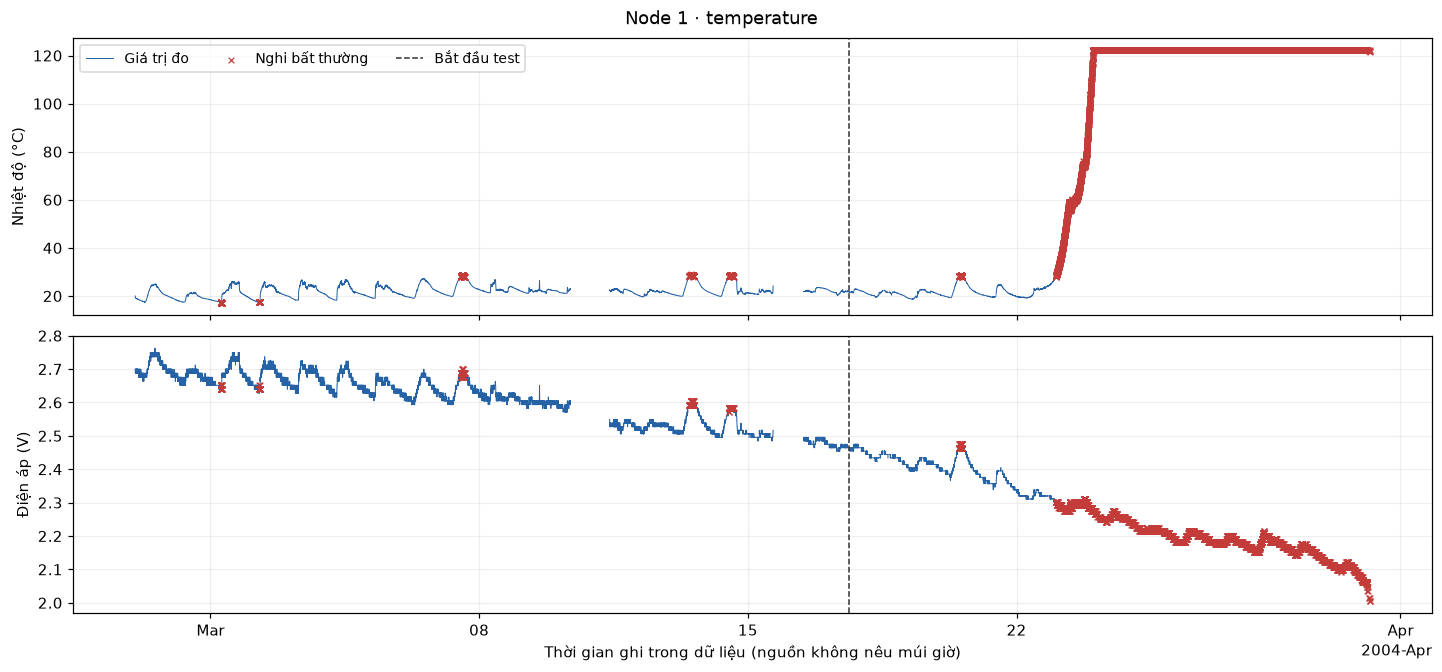

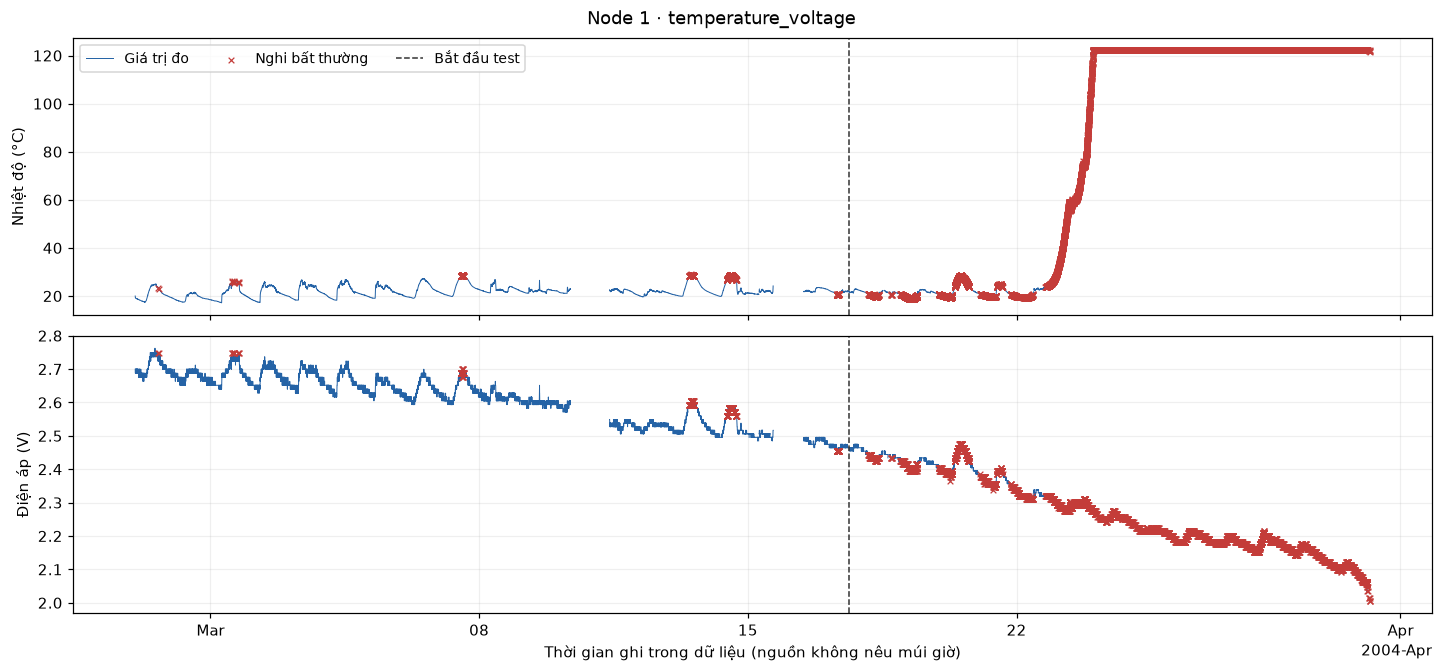

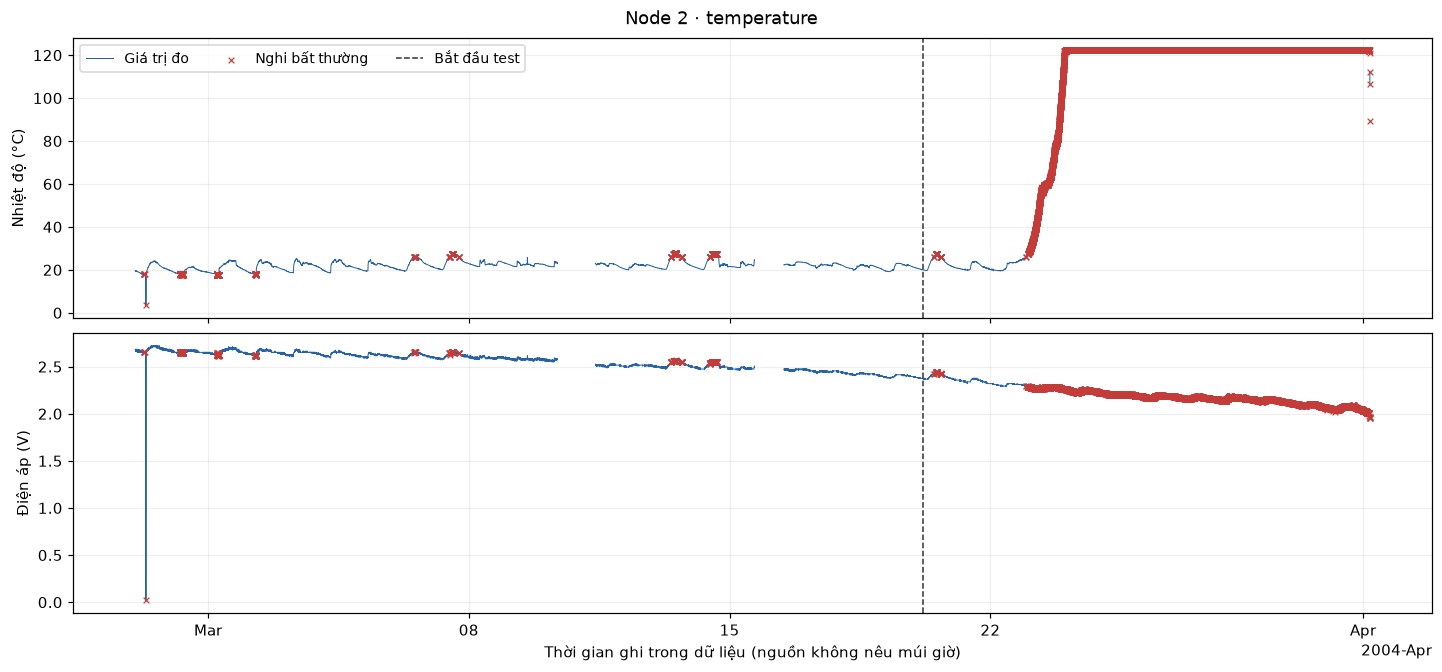

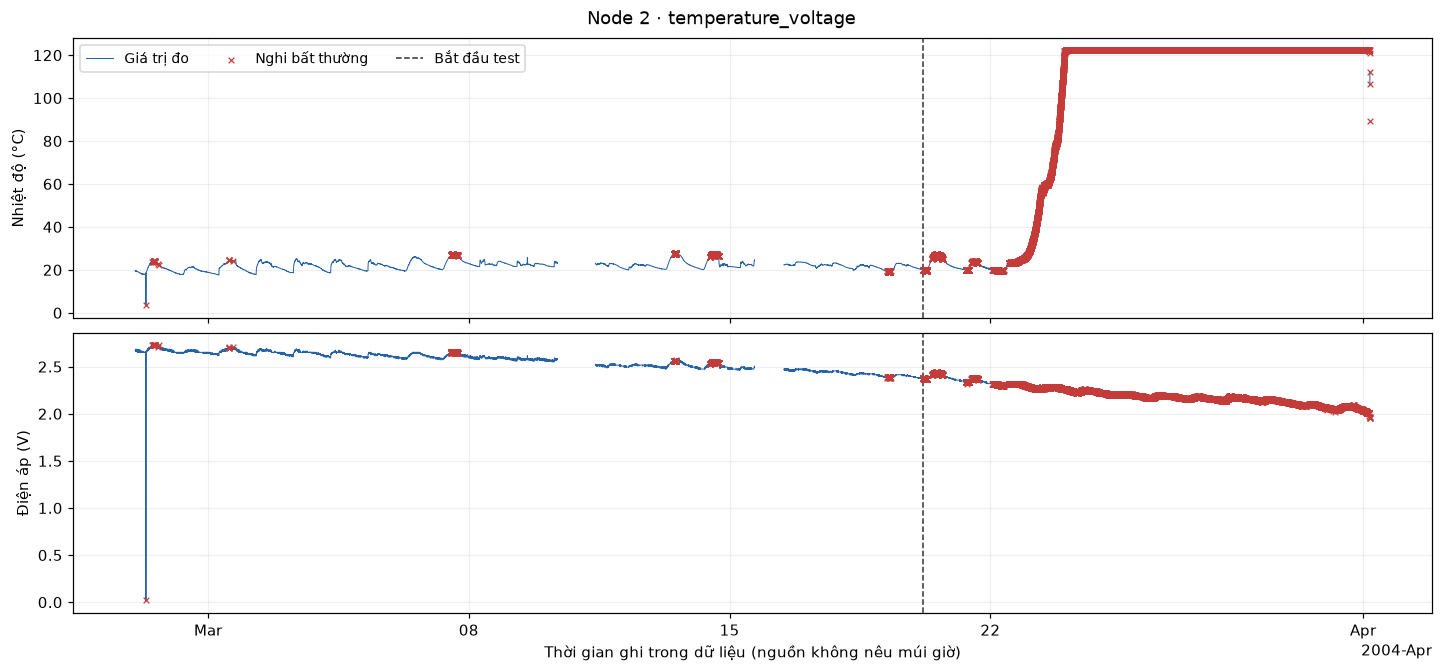

,node_id,n_test,temperature_flags,temperature_voltage_flags,both_flags,temperature_only_flags,temperature_voltage_only_flags,jaccard
0,1,12915,6991,9988,6991,0,2997,0.700
1,2,14075,9399,11526,9399,0,2127,0.815


In [5]:
def plot_timeseries(frame, boundary, title, path):
    frame = frame.sort_values(["timestamp", "raw_line"])
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, layout="constrained")
    gap = frame["timestamp"].diff().dt.total_seconds().gt(300).to_numpy()
    # Chèn NaN trước điểm sau khoảng trống, vẫn giữ chính điểm đo đó.
    positions = np.flatnonzero(gap)
    plot_times = np.insert(frame["timestamp"].to_numpy(), positions,
                           frame["timestamp"].to_numpy()[positions])
    for ax, feature, label in zip(axes, ["temperature", "voltage"], ["Nhiệt độ (°C)", "Điện áp (V)"]):
        plot_values = np.insert(frame[feature].to_numpy(), positions, np.nan)
        ax.plot(plot_times, plot_values, color="#2563a6", linewidth=0.65, label="Giá trị đo")
        flagged = frame.loc[frame["is_anomaly"]]
        ax.scatter(flagged["timestamp"], flagged[feature], marker="x", s=14,
                   color="#c43c39", linewidths=0.8, label="Nghi bất thường", zorder=3)
        if frame["timestamp"].min() <= boundary <= frame["timestamp"].max():
            ax.axvline(boundary, color="#333333", linestyle="--", linewidth=1, label="Bắt đầu test")
        ax.set_ylabel(label)
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    axes[-1].xaxis.set_major_locator(locator)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    axes[-1].set_xlabel("Thời gian ghi trong dữ liệu (nguồn không nêu múi giờ)")
    axes[0].legend(loc="upper left", ncols=3, fontsize=9)
    fig.suptitle(title)
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)


for (node, feature_set), result in predictions.groupby(["node_id", "feature_set"], sort=True):
    boundary = splits[node][1]["timestamp"].min()
    plot_timeseries(result, boundary, f"Node {node} · {feature_set}",
                    FIG_DIR / f"node_{node}_{feature_set}.png")

comparison_rows = []
for node, result in predictions.loc[predictions["split"].eq("test")].groupby("node_id"):
    flags = result.pivot(index="raw_line", columns="feature_set", values="is_anomaly")
    a, b = flags["temperature"], flags["temperature_voltage"]
    union = int((a | b).sum())
    comparison_rows.append({
        "node_id": node, "n_test": len(flags),
        "temperature_flags": int(a.sum()), "temperature_voltage_flags": int(b.sum()),
        "both_flags": int((a & b).sum()),
        "temperature_only_flags": int((a & ~b).sum()),
        "temperature_voltage_only_flags": int((~a & b).sum()),
        "jaccard": int((a & b).sum()) / union if union else 1.0,
    })
feature_comparison = pd.DataFrame(comparison_rows)
display(feature_comparison.round(3))


## 6. Đánh giá bằng bất thường mô phỏng trên test

Tạo một bản sao test cho mỗi node, thay đổi khoảng 5% số điểm thành hai nhóm không giao nhau: **xung nhiệt độ tăng/giảm** và **sụt điện áp**. Biên độ dựa vào IQR của train với mức tối thiểu 12°C và 0,5 V. Đây là kịch bản biến đổi mạnh để kiểm thử; không khẳng định mô phỏng đúng cơ chế hỏng phần cứng.

Cùng vị trí và giá trị mô phỏng được dùng cho mọi cấu hình. Không fit lại mô hình/scaler. Cấu hình chỉ nhiệt độ không quan sát được can thiệp chỉ điện áp. Báo cáo Recall riêng từng loại để thấy giới hạn này.

Nhãn 1 nghĩa là **điểm đã được chèn bất thường**; nhãn 0 nghĩa là **điểm không bị sửa**, chưa chắc là bình thường. Precision = TP/(TP+FP), Recall = TP/(TP+FN), F1 là trung bình điều hòa. Các chỉ số chỉ có ý nghĩa với giả định nền chưa sửa là âm tính; bất thường thật có sẵn hoặc thay đổi phân phối có thể làm Precision thấp. Không dùng chúng làm độ chính xác phát hiện lỗi thực tế.


,node_id,feature_set,n_test,n_injected,precision,recall,f1,tn,fp,fn,tp,unchanged_flag_rate,recall_temperature_spike,recall_voltage_drop
0,1,temperature,12915,644,0.0719,0.7981,0.1319,5636,6635,130,514,0.5407,1.0000,0.5963
1,1,temperature_voltage,12915,644,0.0585,0.9146,0.1100,2792,9479,55,589,0.7725,1.0000,0.8292
2,2,temperature,14075,702,0.0613,0.8333,0.1143,4421,8952,117,585,0.6694,0.9943,0.6724
3,2,temperature_voltage,14075,702,0.0563,0.9316,0.1062,2410,10963,48,654,0.8198,0.9972,0.8661


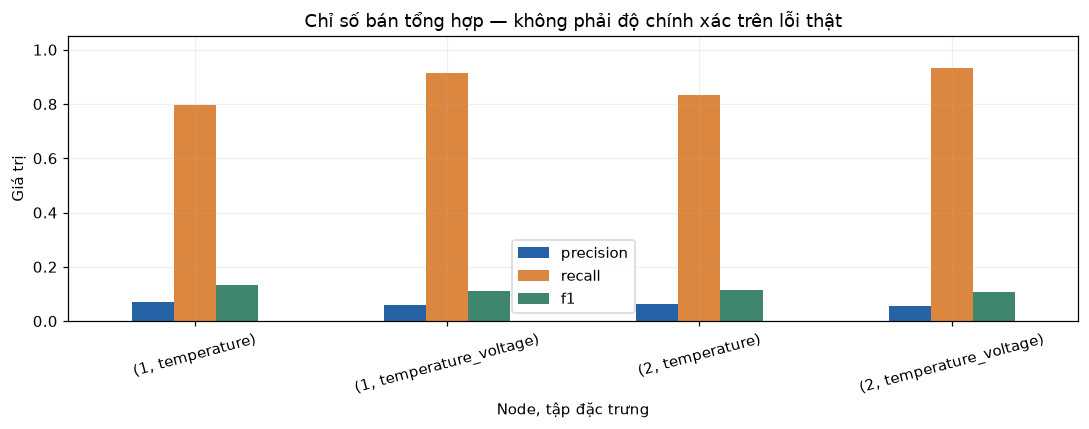

In [6]:
def inject_anomalies(train, test, seed):
    simulated = test.copy(deep=True)
    simulated["original_temperature"] = test["temperature"]
    simulated["original_voltage"] = test["voltage"]
    simulated["injection_type"] = "none"
    rng = np.random.default_rng(seed)
    per_type = max(1, int(len(test) * INJECTION_RATE / 2))
    positions = rng.choice(len(test), size=2 * per_type, replace=False)
    temperature_rows = simulated.index[positions[:per_type]]
    voltage_rows = simulated.index[positions[per_type:]]
    iqr = train[["temperature", "voltage"]].quantile(0.75) - train[["temperature", "voltage"]].quantile(0.25)
    temp_delta = max(12.0, 6 * iqr["temperature"])
    voltage_delta = max(0.5, 6 * iqr["voltage"])
    simulated.loc[temperature_rows, "temperature"] += rng.choice([-1, 1], per_type) * temp_delta
    simulated.loc[voltage_rows, "voltage"] -= voltage_delta
    simulated.loc[temperature_rows, "injection_type"] = "temperature_spike"
    simulated.loc[voltage_rows, "injection_type"] = "voltage_drop"
    simulated["injected"] = simulated["injection_type"].ne("none")
    return simulated


synthetic_parts, metric_rows = [], []
for node, (train, test) in splits.items():
    simulated = inject_anomalies(train, test, RANDOM_STATE + int(node))
    for feature_set, features in FEATURE_SETS.items():
        model = models[node, feature_set]
        result = simulated.copy()
        result["feature_set"] = feature_set
        result["decision_score"] = model.decision_function(result[features])
        result["is_anomaly"] = model.predict(result[features]) == -1
        synthetic_parts.append(result)
        precision, recall, f1, _ = precision_recall_fscore_support(
            result["injected"], result["is_anomaly"], average="binary", zero_division=0
        )
        tn, fp, fn, tp = confusion_matrix(
            result["injected"], result["is_anomaly"], labels=[False, True]
        ).ravel()
        row = {
            "node_id": node, "feature_set": feature_set, "n_test": len(result),
            "n_injected": int(result["injected"].sum()), "precision": precision,
            "recall": recall, "f1": f1, "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "unchanged_flag_rate": result.loc[~result["injected"], "is_anomaly"].mean(),
        }
        for kind in ["temperature_spike", "voltage_drop"]:
            row[f"recall_{kind}"] = result.loc[result["injection_type"].eq(kind), "is_anomaly"].mean()
        metric_rows.append(row)

synthetic_predictions = pd.concat(synthetic_parts, ignore_index=True)
synthetic_metrics = pd.DataFrame(metric_rows)
display(synthetic_metrics.round(4))
ax = synthetic_metrics.set_index(["node_id", "feature_set"])[["precision", "recall", "f1"]].plot(
    kind="bar", figsize=(10, 4), ylim=(0, 1.05), rot=15, color=["#2563a6", "#dc8740", "#40866c"]
)
ax.set_title("Chỉ số bán tổng hợp — không phải độ chính xác trên lỗi thật")
ax.set_ylabel("Giá trị")
ax.set_xlabel("Node, tập đặc trưng")
ax.figure.tight_layout()
ax.figure.savefig(FIG_DIR / "synthetic_metrics.png", dpi=150)
plt.show()
plt.close(ax.figure)


## 7. Kiểm tra thủ công

Bảng gợi ý lấy tối đa 5 điểm có score thấp nhất trong nhóm bị đánh dấu và 5 điểm không bị đánh dấu ngẫu nhiên cho từng node/cấu hình trên test. Đây là mẫu để xem xét, **không đủ để ước lượng độ chính xác toàn bộ dữ liệu**. Nếu không còn điểm không bị đánh dấu, bảng không có nhóm đối chứng tương ứng.

Hai cửa sổ mẫu bên dưới cho mỗi node giúp xem chi tiết: một điểm bị đánh dấu và một điểm đối chứng (nếu có), dùng cấu hình nhiệt độ + điện áp. Các điểm cực đoan có thể làm đồ thị toàn kỳ khó nhìn, vì vậy nên kiểm tra thêm cửa sổ quanh các dòng khác trong CSV.

Điền `manual_label` bằng `nghi_bat_thuong`, `hop_ly` hoặc `chua_ro`, và ghi lý do trong `notes`. Việc chưa xem một điểm không tương đương đã xác nhận nó bình thường.


,node_id,feature_set,raw_line,timestamp,review_reason,decision_score
0,1,temperature,22347,2004-03-23 00:55:29.464999,lowest_score_flag,-0.067225
1,1,temperature,22350,2004-03-23 00:57:29.532201,lowest_score_flag,-0.067225
2,1,temperature,22352,2004-03-23 00:57:59.221765,lowest_score_flag,-0.067225
3,1,temperature,22357,2004-03-23 01:00:58.608117,lowest_score_flag,-0.067225
4,1,temperature,22360,2004-03-23 01:02:08.627799,lowest_score_flag,-0.067225
5,1,temperature,40158,2004-03-19 12:18:06.665492,unflagged_control,0.212367
6,1,temperature,39082,2004-03-18 11:03:46.609024,unflagged_control,0.227541
7,1,temperature,20083,2004-03-22 04:37:09.927815,unflagged_control,0.139941
8,1,temperature,40640,2004-03-19 21:00:20.456736,unflagged_control,0.220340
9,1,temperature,42960,2004-03-21 17:19:59.917330,unflagged_control,0.224972


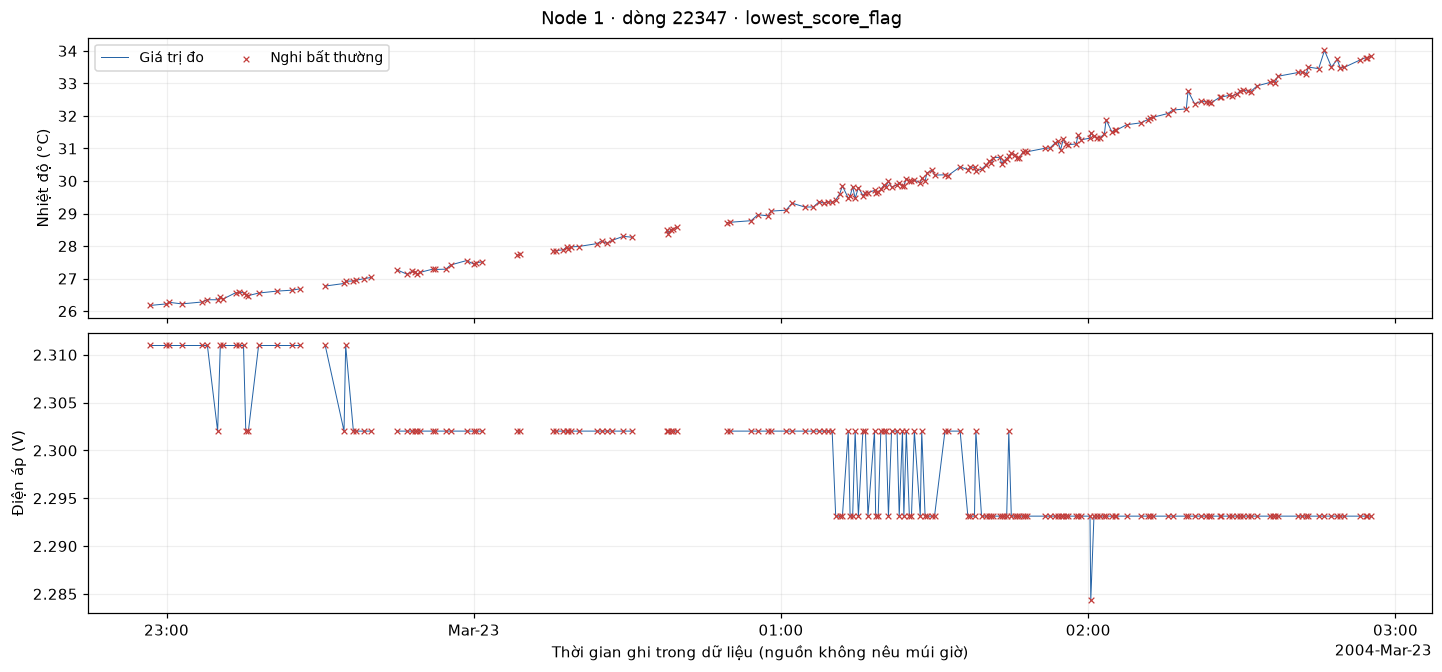

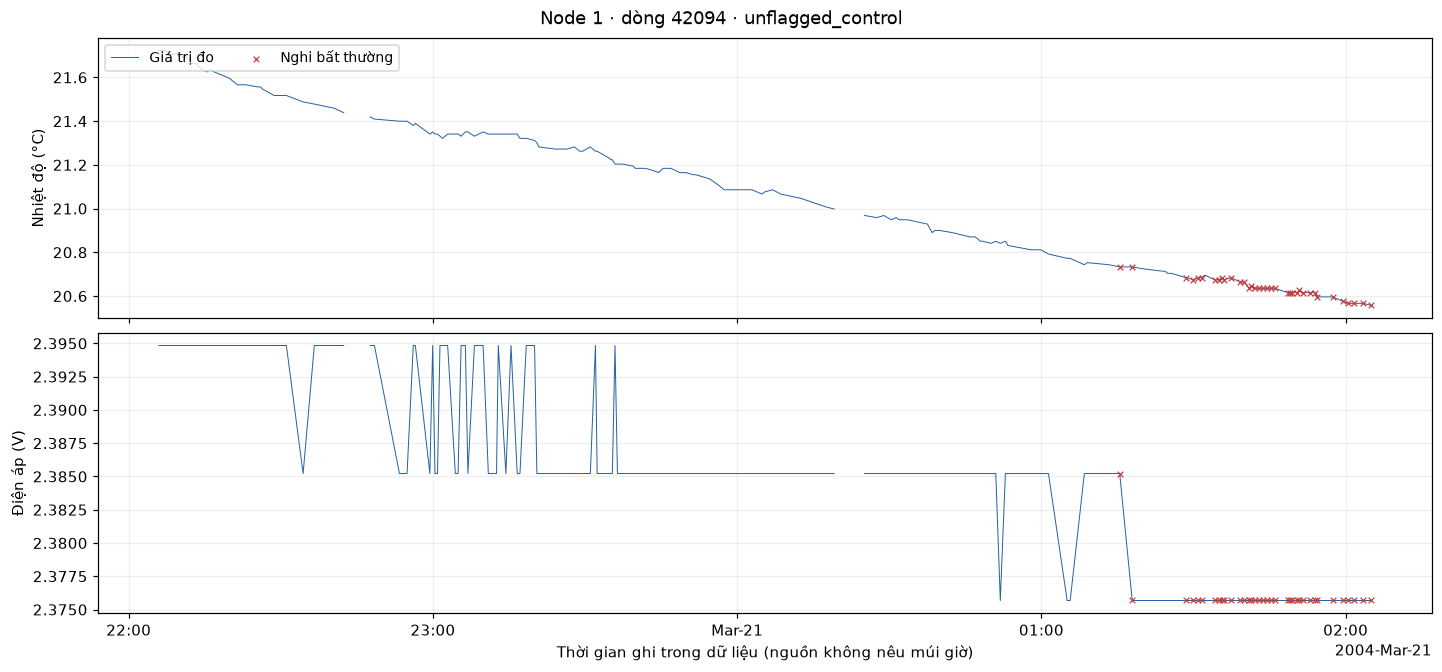

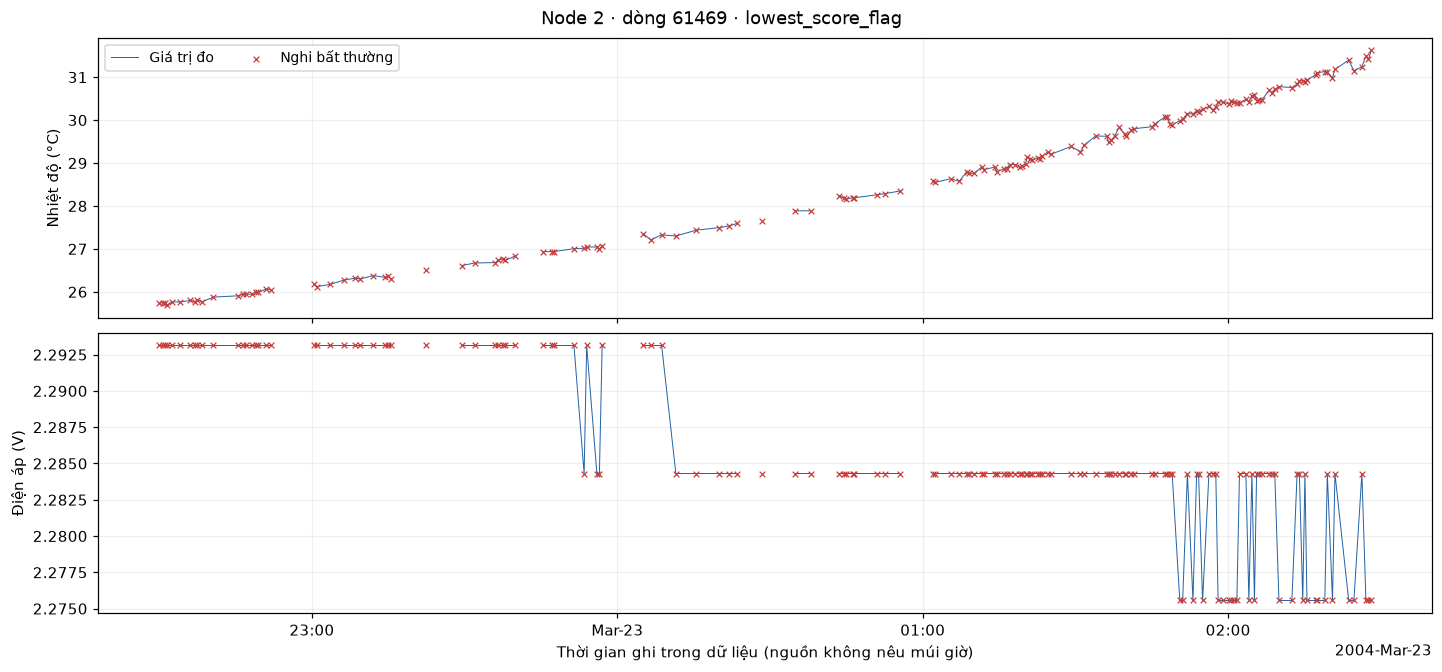

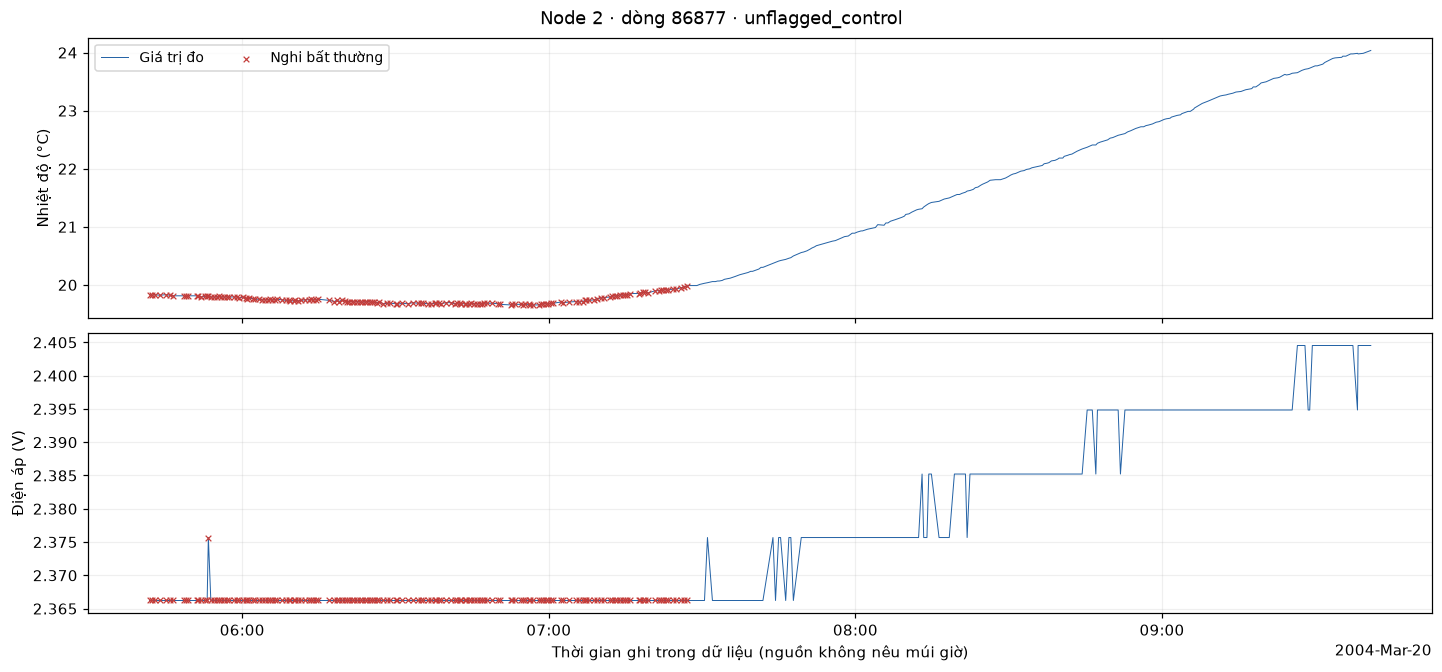

In [7]:
review_parts = []
for (node, feature_set), result in predictions.loc[predictions["split"].eq("test")].groupby(["node_id", "feature_set"]):
    flagged = result.loc[result["is_anomaly"]].nsmallest(5, "decision_score").copy()
    flagged["review_reason"] = "lowest_score_flag"
    normal = result.loc[~result["is_anomaly"]]
    controls = normal.sample(n=min(5, len(normal)), random_state=RANDOM_STATE).copy()
    controls["review_reason"] = "unflagged_control"
    review_parts.extend([flagged, controls])
manual_review = pd.concat(review_parts, ignore_index=True)
manual_review["manual_label"] = ""
manual_review["notes"] = ""
display(manual_review[["node_id", "feature_set", "raw_line", "timestamp", "review_reason", "decision_score"]])

for node in NODE_IDS:
    candidates = manual_review.loc[
        manual_review["node_id"].eq(node) & manual_review["feature_set"].eq("temperature_voltage")
    ].groupby("review_reason", sort=True).head(1)
    result = predictions.loc[
        predictions["node_id"].eq(node) & predictions["feature_set"].eq("temperature_voltage")
    ]
    for row in candidates.itertuples():
        window = result.loc[result["timestamp"].between(
            row.timestamp - pd.Timedelta(hours=2), row.timestamp + pd.Timedelta(hours=2)
        )]
        plot_timeseries(window, splits[node][1]["timestamp"].min(),
                        f"Node {node} · dòng {row.raw_line} · {row.review_reason}",
                        FIG_DIR / f"review_node_{node}_{row.review_reason}.png")


## 8. Tự kiểm tra và xuất kết quả

Các assert bên dưới kiểm tra parser, đếm số dòng, thứ tự thời gian, phân tách train/test, việc chỉ fit scaler trên train, tính nhất quán nhãn/score và việc mô phỏng không sửa dữ liệu thật. CSV giữ đơn vị đo gốc, không thay bằng giá trị đã chuẩn hóa.

Các tệp kết quả thông thường được ghi đè khi Run All. `manual_review.csv` chỉ được tạo lần đầu để không mất ghi chú; nếu đổi cấu hình, đổi tên tệp nhận xét cũ trước khi chạy lại để tạo bộ phiếu mới. Metadata lưu cấu hình, phiên bản thư viện, hash dữ liệu và ngưỡng thời gian.


In [8]:
assert cleaning_report.eval(
    "raw_rows == invalid_timestamp + missing_or_nonfinite_features + exact_duplicates + clean_rows"
).all()
assert len(predictions) == len(clean) * len(FEATURE_SETS)
assert len(anomalies) == int(predictions["is_anomaly"].sum())
assert predictions["is_anomaly"].eq(predictions["decision_score"].lt(0)).all()
assert np.isfinite(clean[REQUIRED_FEATURES].to_numpy(dtype=float)).all()

for node, (train, test) in splits.items():
    assert train["timestamp"].is_monotonic_increasing and test["timestamp"].is_monotonic_increasing
    assert set(train["raw_line"]).isdisjoint(test["raw_line"])
    assert train["timestamp"].max() < test["timestamp"].min()
    before_train, before_test = train.copy(deep=True), test.copy(deep=True)
    injected_a = inject_anomalies(train, test, RANDOM_STATE + int(node))
    injected_b = inject_anomalies(train, test, RANDOM_STATE + int(node))
    pd.testing.assert_frame_equal(train, before_train)
    pd.testing.assert_frame_equal(test, before_test)
    pd.testing.assert_frame_equal(injected_a, injected_b)
    expected_injected = 2 * max(1, int(len(test) * INJECTION_RATE / 2))
    assert int(injected_a["injected"].sum()) == expected_injected
    changed = injected_a[["temperature", "voltage"]].ne(test[["temperature", "voltage"]])
    assert changed.any(axis=1).eq(injected_a["injected"]).all()
    assert not changed.all(axis=1).any()
    for feature_set, features in FEATURE_SETS.items():
        np.testing.assert_allclose(
            models[node, feature_set].named_steps["standardscaler"].mean_,
            train[features].mean().to_numpy(),
        )
    synthetic_node = synthetic_predictions.loc[synthetic_predictions["node_id"].eq(node)]
    assert synthetic_node.groupby("raw_line")[["temperature", "voltage", "injection_type"]].nunique().eq(1).all().all()
    # Can thiệp chỉ điện áp không thể thay đổi dự đoán của mô hình chỉ nhiệt độ.
    temperature_sim = synthetic_node.loc[synthetic_node["feature_set"].eq("temperature")].set_index("raw_line")
    temperature_original = predictions.loc[
        predictions["node_id"].eq(node) & predictions["feature_set"].eq("temperature")
        & predictions["split"].eq("test")
    ].set_index("raw_line")
    voltage_rows = temperature_sim.index[temperature_sim["injection_type"].eq("voltage_drop")]
    assert temperature_sim.loc[voltage_rows, "is_anomaly"].equals(
        temperature_original.loc[voltage_rows, "is_anomaly"]
    )

tables = {
    DATA_CHECK_DIR: {"cleaning_report": cleaning_report, "node_profile": node_profile},
    PREDICTION_DIR: {
        "predictions": predictions, "anomalies": anomalies, "anomaly_summary": anomaly_summary,
    },
    EVALUATION_DIR: {
        "feature_comparison": feature_comparison, "synthetic_metrics": synthetic_metrics,
        "synthetic_predictions": synthetic_predictions,
    },
}
for directory, reports in tables.items():
    for name, table in reports.items():
        table.to_csv(directory / f"{name}.csv", index=False, encoding="utf-8-sig")

review_path = EVALUATION_DIR / "manual_review.csv"
if not review_path.exists():
    manual_review.to_csv(review_path, index=False, encoding="utf-8-sig")
else:
    print(f"Giữ nguyên {review_path} để bảo toàn nhận xét cũ.")

metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "source_url": DATA_URL,
    "raw_path": str(RAW_PATH), "raw_sha256": raw_sha256, "raw_bytes": RAW_PATH.stat().st_size,
    "load_audit": load_audit, "node_ids": NODE_IDS, "feature_sets": FEATURE_SETS,
    "train_fraction": TRAIN_FRACTION, "contamination": CONTAMINATION,
    "random_state": RANDOM_STATE, "n_estimators": N_ESTIMATORS, "injection_rate": INJECTION_RATE,
    "test_start_per_node": {str(node): str(test["timestamp"].min()) for node, (_, test) in splits.items()},
    "python": platform.python_version(),
    "versions": {name: importlib.metadata.version(name) for name in
                 ["numpy", "pandas", "scikit-learn", "matplotlib", "nbclient"]},
    "evaluation_note": "Semi-synthetic labels identify injected rows, not confirmed real faults.",
}
(OUT_DIR / "run_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
assert len(pd.read_csv(PREDICTION_DIR / "anomalies.csv")) == len(anomalies)
print("PASS: các tự kiểm tra đã hoàn tất.")
print(f"Kết quả: {OUT_DIR.resolve()}")


PASS: các tự kiểm tra đã hoàn tất.
Kết quả: D:\Project\NT120\outputs


## 9. Gợi ý viết phần nhận xét

- Từ `cleaning_report` và `node_profile`: node nào thiếu nhiều dữ liệu, có khoảng ngắt dài hoặc dải giá trị khác thường?
- Từ `anomaly_summary`: so sánh train và test riêng; nếu test bị đánh dấu nhiều, kiểm tra drift và các cụm giá trị cuối kỳ.
- Từ `feature_comparison`: hai tập đặc trưng cùng đánh dấu bao nhiêu điểm? Jaccard gần 1 nghĩa là tập điểm đánh dấu gần giống nhau; quy ước 1 khi cả hai tập rỗng.
- Từ biểu đồ và phiếu thủ công: điểm bị đánh dấu là xung đơn lẻ, thay đổi kéo dài, điện áp giảm hay biến thiên môi trường hợp lý? Mô tả bằng chứng trước khi suy đoán nguyên nhân.
- Từ `synthetic_metrics`: đọc Precision/Recall/F1 cùng Recall theo loại can thiệp và tỷ lệ đánh dấu trên nền không sửa. Không kết luận cấu hình nào tốt hơn trên lỗi thật chỉ từ các chỉ số này.

**Giới hạn:** chưa có nhãn lỗi thực; chưa xác minh chuyên gia; hai node không đại diện toàn mạng; mô hình chưa có độ trễ/đặc trưng theo cửa sổ nên có thể bỏ sót bất thường theo ngữ cảnh hoặc cảm biến bị kẹt ở giá trị phổ biến. Tỷ lệ contamination và kịch bản mô phỏng ảnh hưởng kết quả.

**Ghi nhận dữ liệu:** Peter Bodik, Wei Hong, Carlos Guestrin, Sam Madden, Mark Paskin và Romain Thibaux; Intel Berkeley Research Lab; TinyDB/TinyOS. [Trang nguồn và điều kiện sử dụng](https://db.csail.mit.edu/labdata/labdata.html).
